In [ ]:

import torch
import numpy as np
import matplotlib
import sys

print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("NumPy:", np.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU memory:", round(
        torch.cuda.get_device_properties(0).total_memory / 1024**3, 2
    ), "GB")
else:
    print("GPU not detected. Check runtime settings.")


Python: 3.13.18
PyTorch: 2.14.1+cpu
NumPy: 2.4.6
CUDA available: False
GPU not detected. Check runtime settings.


In [ ]:
%pip install -q rasterio matplotlib scikit-learn tqdm pandas

In [ ]:
import rasterio
import matplotlib
import sklearn
import pandas
import torch

print("Rasterio:", rasterio.__version__)
print("Matplotlib:", matplotlib.__version__)
print("Scikit-learn:", sklearn.__version__)
print("PyTorch:", torch.__version__)
print("Setup successful.")

Rasterio: 1.5.2
Matplotlib: 3.10.0
Scikit-learn: 1.6.1
PyTorch: 2.14.1+cpu
Setup successful.


**Data Acquisition**

In [ ]:

import os
import subprocess

folders = [
    "S1Hand",
    "S2Hand",
    "LabelHand"
]

base = "gs://sen1floods11/v1.1/data/flood_events/HandLabeled"

for folder in folders:
    path = f"{base}/{folder}/"
    print(f"\n{folder}:")
    result = subprocess.run(
        ["gsutil", "ls", path],
        capture_output=True,
        text=True
    )
    print("\n".join(result.stdout.splitlines()[:5]))
    if result.returncode != 0:
        print(result.stderr[:500])


S1Hand:
gs://sen1floods11/v1.1/data/flood_events/HandLabeled/S1Hand/Bolivia_103757_S1Hand.tif
gs://sen1floods11/v1.1/data/flood_events/HandLabeled/S1Hand/Bolivia_129334_S1Hand.tif
gs://sen1floods11/v1.1/data/flood_events/HandLabeled/S1Hand/Bolivia_195474_S1Hand.tif
gs://sen1floods11/v1.1/data/flood_events/HandLabeled/S1Hand/Bolivia_23014_S1Hand.tif
gs://sen1floods11/v1.1/data/flood_events/HandLabeled/S1Hand/Bolivia_233925_S1Hand.tif

S2Hand:
gs://sen1floods11/v1.1/data/flood_events/HandLabeled/S2Hand/Bolivia_103757_S2Hand.tif
gs://sen1floods11/v1.1/data/flood_events/HandLabeled/S2Hand/Bolivia_129334_S2Hand.tif
gs://sen1floods11/v1.1/data/flood_events/HandLabeled/S2Hand/Bolivia_195474_S2Hand.tif
gs://sen1floods11/v1.1/data/flood_events/HandLabeled/S2Hand/Bolivia_23014_S2Hand.tif
gs://sen1floods11/v1.1/data/flood_events/HandLabeled/S2Hand/Bolivia_233925_S2Hand.tif

LabelHand:
gs://sen1floods11/v1.1/data/flood_events/HandLabeled/LabelHand/Bolivia_103757_LabelHand.tif
gs://sen1floods11/v1

**Downloading our first 5 samples**

In [ ]:

import os
import subprocess

base = "gs://sen1floods11/v1.1/data/flood_events/HandLabeled"

sample_ids = [
    "Bolivia_103757",
    "Bolivia_129334",
    "Bolivia_195474",
    "Bolivia_23014",
    "Bolivia_233925"
]

folders = ["S1Hand", "S2Hand", "LabelHand"]

for folder in folders:
    os.makedirs(f"data/{folder}", exist_ok=True)

    for sample_id in sample_ids:
        suffix = folder.replace("Hand", "Hand")
        filename = f"{sample_id}_{suffix}.tif"

        source = f"{base}/{folder}/{filename}"
        destination = f"data/{folder}/{filename}"

        subprocess.run(
            ["gsutil", "cp", source, destination],
            check=True
        )

print("Download complete.")

Download complete.


**Inspect the downoaded images**

In [ ]:

import rasterio
import glob
import os

for folder in ["S1Hand", "S2Hand", "LabelHand"]:
    print(f"\n--- {folder} ---")

    for path in sorted(glob.glob(f"data/{folder}/*.tif")):
        with rasterio.open(path) as src:
            print(
                os.path.basename(path),
                "| Shape:", (src.height, src.width),
                "| Bands:", src.count,
                "| CRS:", src.crs
            )


--- S1Hand ---
Bolivia_103757_S1Hand.tif | Shape: (512, 512) | Bands: 2 | CRS: EPSG:4326
Bolivia_129334_S1Hand.tif | Shape: (512, 512) | Bands: 2 | CRS: EPSG:4326
Bolivia_195474_S1Hand.tif | Shape: (512, 512) | Bands: 2 | CRS: EPSG:4326
Bolivia_23014_S1Hand.tif | Shape: (512, 512) | Bands: 2 | CRS: EPSG:4326
Bolivia_233925_S1Hand.tif | Shape: (512, 512) | Bands: 2 | CRS: EPSG:4326

--- S2Hand ---
Bolivia_103757_S2Hand.tif | Shape: (512, 512) | Bands: 13 | CRS: EPSG:4326
Bolivia_129334_S2Hand.tif | Shape: (512, 512) | Bands: 13 | CRS: EPSG:4326
Bolivia_195474_S2Hand.tif | Shape: (512, 512) | Bands: 13 | CRS: EPSG:4326
Bolivia_23014_S2Hand.tif | Shape: (512, 512) | Bands: 13 | CRS: EPSG:4326
Bolivia_233925_S2Hand.tif | Shape: (512, 512) | Bands: 13 | CRS: EPSG:4326

--- LabelHand ---
Bolivia_103757_LabelHand.tif | Shape: (512, 512) | Bands: 1 | CRS: EPSG:4326
Bolivia_129334_LabelHand.tif | Shape: (512, 512) | Bands: 1 | CRS: EPSG:4326
Bolivia_195474_LabelHand.tif | Shape: (512, 512) | B

All 15 files have matching dimensions and coordinate systems, but this does not mean that the images are pixel-aligned. We need to check that before training

In [ ]:

import rasterio
import numpy as np

sample = "Bolivia_103757"

files = {
    "SAR": f"data/S1Hand/{sample}_S1Hand.tif",
    "Optical": f"data/S2Hand/{sample}_S2Hand.tif",
    "Label": f"data/LabelHand/{sample}_LabelHand.tif"
}

for name, path in files.items():
    with rasterio.open(path) as src:
        data = src.read()

        print(f"\n{name}")
        print("Transform:", src.transform)
        print("Bounds:", src.bounds)
        print("NoData:", src.nodata)
        print("Unique values:", np.unique(data)[:20])
        print("Min:", np.nanmin(data))
        print("Max:", np.nanmax(data))
        print("NaN count:", np.isnan(data).sum())


SAR
Transform: | 0.00, 0.00,-65.27|
| 0.00,-0.00,-14.21|
| 0.00, 0.00, 1.00|
Bounds: BoundingBox(left=-65.26512067407877, bottom=-14.258060189545045, right=-65.21912693153185, top=-14.212066446998126)
NoData: nan
Unique values: [-48.24836  -48.247437 -48.247402 -48.247356 -48.246696 -48.246536
 -48.246334 -48.246315 -48.246292 -48.244846 -48.24392  -48.24379
 -48.243706 -48.24369  -48.243683 -48.243633 -48.24354  -48.243523
 -48.24172  -48.241592]
Min: -48.24836
Max: -0.69059896
NaN count: 321042

Optical
Transform: | 0.00, 0.00,-65.27|
| 0.00,-0.00,-14.21|
| 0.00, 0.00, 1.00|
Bounds: BoundingBox(left=-65.26512067407877, bottom=-14.258060189545045, right=-65.21912693153185, top=-14.212066446998126)
NoData: 0.0
Unique values: [ 0  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22]
Min: 0
Max: 5662
NaN count: 0

Label
Transform: | 0.00, 0.00,-65.27|
| 0.00,-0.00,-14.21|
| 0.00, 0.00, 1.00|
Bounds: BoundingBox(left=-65.26512067407877, bottom=-14.258060189545049, right=-65.219126931

All three files have matching bounds and 512 × 512 dimensions, with only a negligible difference in the label bounds

**inspect labels and missing data**

In [ ]:

import rasterio
import numpy as np

sample = "Bolivia_103757"

for name, path in {
    "SAR": f"data/S1Hand/{sample}_S1Hand.tif",
    "Optical": f"data/S2Hand/{sample}_S2Hand.tif",
    "Label": f"data/LabelHand/{sample}_LabelHand.tif"
}.items():
    with rasterio.open(path) as src:
        arr = src.read()

        print(f"\n{name}")
        print("Array shape:", arr.shape)
        print("NaNs per band:", np.isnan(arr).sum(axis=(1, 2)))
        print("Valid pixels per band:", np.isfinite(arr).sum(axis=(1, 2)))

        if name == "Label":
            values, counts = np.unique(arr, return_counts=True)
            print("Label distribution:", dict(zip(values, counts)))


SAR
Array shape: (2, 512, 512)
NaNs per band: [160521 160521]
Valid pixels per band: [101623 101623]

Optical
Array shape: (13, 512, 512)
NaNs per band: [0 0 0 0 0 0 0 0 0 0 0 0 0]
Valid pixels per band: [262144 262144 262144 262144 262144 262144 262144 262144 262144 262144
 262144 262144 262144]

Label
Array shape: (1, 512, 512)
NaNs per band: [0]
Valid pixels per band: [262144]
Label distribution: {np.int16(-1): np.int64(174067), np.int16(0): np.int64(52715), np.int16(1): np.int64(35362)}


Only 33.6% of pixels have usable ground-truth labels.

SAR has:
- 160,521 missing pixels per band.
- 101,623 valid pixels per band.
- Both SAR bands have identical missing-pixel counts.

This means we must handle missing sensor data explicitly, rather than treating missing values as actual measurements.

**Visual Inspection**

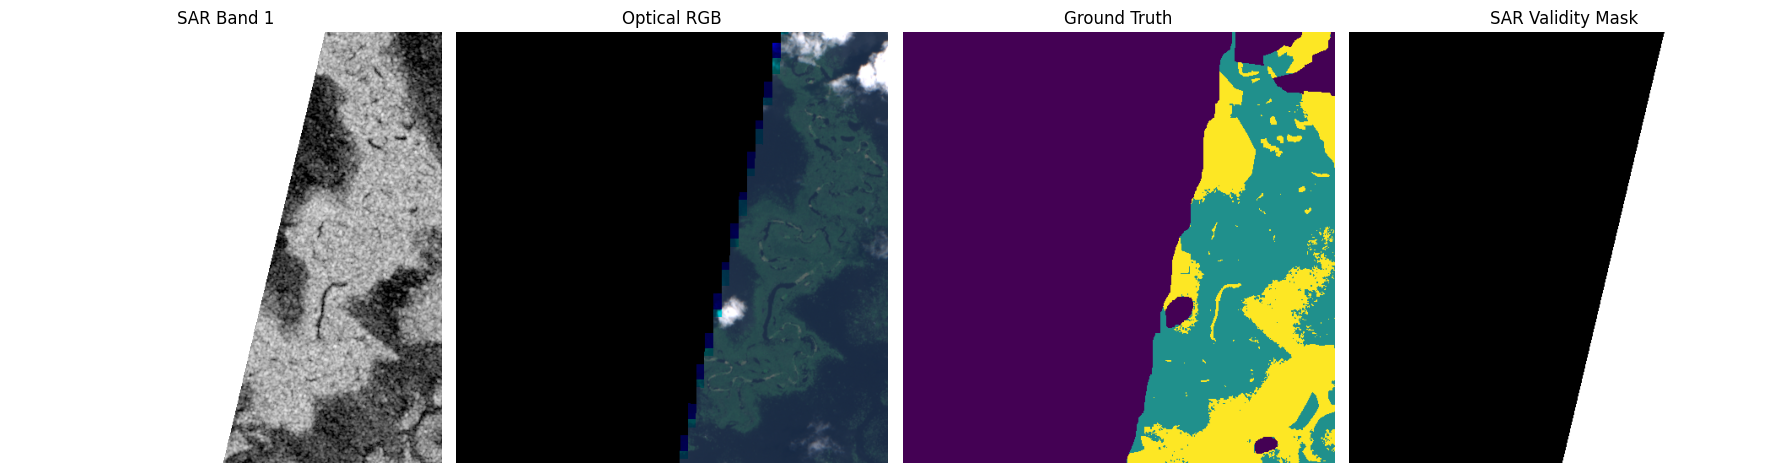

In [ ]:

import rasterio
import numpy as np
import matplotlib.pyplot as plt

sample = "Bolivia_103757"

with rasterio.open(f"data/S1Hand/{sample}_S1Hand.tif") as src:
    sar = src.read()

with rasterio.open(f"data/S2Hand/{sample}_S2Hand.tif") as src:
    optical = src.read()

with rasterio.open(f"data/LabelHand/{sample}_LabelHand.tif") as src:
    labels = src.read(1)

fig, ax = plt.subplots(1, 4, figsize=(18, 5))

ax[0].imshow(sar[0], cmap="gray", vmin=-25, vmax=0)
ax[0].set_title("SAR Band 1")

ax[1].imshow(optical[[3, 2, 1]].transpose(1, 2, 0) / 3000)
ax[1].set_title("Optical RGB")

ax[2].imshow(labels, cmap="viridis", vmin=-1, vmax=1)
ax[2].set_title("Ground Truth")

ax[3].imshow(np.isfinite(sar[0]), cmap="gray")
ax[3].set_title("SAR Validity Mask")

for a in ax:
    a.axis("off")

plt.tight_layout()
plt.show()

We need to quantify that overlap before deciding how to handle missing data.

**measure sensor coverage against ground truth**

In [ ]:

import rasterio
import numpy as np

sample = "Bolivia_103757"

with rasterio.open(f"data/S1Hand/{sample}_S1Hand.tif") as src:
    sar = src.read()

with rasterio.open(f"data/S2Hand/{sample}_S2Hand.tif") as src:
    optical = src.read()

with rasterio.open(f"data/LabelHand/{sample}_LabelHand.tif") as src:
    labels = src.read(1)

sar_valid = np.isfinite(sar).all(axis=0)
optical_valid = np.all(optical != 0, axis=0)
labelled = labels != -1

conditions = {
    "SAR valid": sar_valid,
    "Optical valid": optical_valid,
    "Both sensors valid": sar_valid & optical_valid,
    "Both sensors valid + labelled": sar_valid & optical_valid & labelled
}

for name, mask in conditions.items():
    print(f"{name}: {mask.sum():,} pixels ({mask.mean()*100:.2f}%)")

print("\nGround truth within both valid sensors:")
for value, name in [(0, "Non-flood"), (1, "Flood")]:
    mask = (labels == value) & sar_valid & optical_valid
    print(f"{name}: {mask.sum():,} pixels")


SAR valid: 101,623 pixels (38.77%)
Optical valid: 87,195 pixels (33.26%)
Both sensors valid: 87,195 pixels (33.26%)
Both sensors valid + labelled: 81,645 pixels (31.15%)

Ground truth within both valid sensors:
Non-flood: 49,209 pixels
Flood: 32,436 pixels


**What this means**

We have enough labelled pixels to begin a small experiment, but this is only one image tile. We cannot assume the same coverage pattern across the dataset.

In [ ]:

import numpy as np
import rasterio

for sample in sample_ids:
    with rasterio.open(f"data/S1Hand/{sample}_S1Hand.tif") as s1, \
         rasterio.open(f"data/S2Hand/{sample}_S2Hand.tif") as s2, \
         rasterio.open(f"data/LabelHand/{sample}_LabelHand.tif") as lab:

        sar = s1.read()
        optical = s2.read()
        labels = lab.read(1)

        sv = np.isfinite(sar).all(axis=0)
        ov = np.all(optical != 0, axis=0)
        labelled = labels != -1
        usable = sv & ov & labelled

        print(
            sample,
            "| Usable:", round(usable.mean()*100, 2), "%",
            "| Flood:", int(((labels == 1) & usable).sum()),
            "| Non-flood:", int(((labels == 0) & usable).sum())
        )

Bolivia_103757 | Usable: 31.15 % | Flood: 32436 | Non-flood: 49209
Bolivia_129334 | Usable: 90.43 % | Flood: 156067 | Non-flood: 80998
Bolivia_195474 | Usable: 99.69 % | Flood: 1551 | Non-flood: 259784
Bolivia_23014 | Usable: 69.81 % | Flood: 7780 | Non-flood: 175215
Bolivia_233925 | Usable: 55.81 % | Flood: 1 | Non-flood: 146293


**Finding geographic diversity**

Before training, we need to find how many different flood events are available,

We need training and testing data from different events. Otherwise, the model might memorise one geographical area and appear more capable than it really is.

In [ ]:

import subprocess
from collections import Counter

base = "gs://sen1floods11/v1.1/data/flood_events/HandLabeled/S1Hand/"

result = subprocess.run(
    ["gsutil", "ls", base],
    capture_output=True,
    text=True,
    check=True
)

files = [x.strip() for x in result.stdout.splitlines() if x.strip()]
events = Counter(
    "_".join(x.rsplit("/", 1)[-1].split("_")[:-2])
    for x in files
)

print("Total SAR tiles:", len(files))
print("Distinct event groups:", len(events))

for event, count in events.most_common():
    print(event, ":", count)

Total SAR tiles: 446
Distinct event groups: 11
USA : 69
India : 68
Paraguay : 67
Ghana : 53
Sri-Lanka : 42
Mekong : 30
Spain : 30
Pakistan : 28
Somalia : 26
Nigeria : 18
Bolivia : 15


In [ ]:
!gsutil ls gs://sen1floods11/v1.1/splits/flood_handlabeled/

Google recommends using Gcloud storage CLI (https://docs.cloud.google.com/storage/docs/discover-object-storage-gcloud) instead of gsutil. Please refer to migration guide (https://docs.cloud.google.com/storage/docs/gsutil-transition-to-gcloud) for assistance.
gs://sen1floods11/v1.1/splits/flood_handlabeled/flood_bolivia_data.csv
gs://sen1floods11/v1.1/splits/flood_handlabeled/flood_test_data.csv
gs://sen1floods11/v1.1/splits/flood_handlabeled/flood_train_data.csv
gs://sen1floods11/v1.1/splits/flood_handlabeled/flood_valid_data.csv


**Download official Split files**

In [ ]:
import os
import requests

os.makedirs("splits", exist_ok=True)

base = "https://storage.googleapis.com/sen1floods11/v1.1/splits/flood_handlabeled"

files = [
    "flood_train_data.csv",
    "flood_valid_data.csv",
    "flood_test_data.csv",
    "flood_bolivia_data.csv"
]

for filename in files:
    url = f"{base}/{filename}"
    response = requests.get(url)
    response.raise_for_status()

    with open(f"splits/{filename}", "wb") as f:
        f.write(response.content)

    print(filename, "downloaded:", len(response.content), "bytes")

print("\nAll split files downloaded.")

flood_train_data.csv downloaded: 13574 bytes
flood_valid_data.csv downloaded: 4804 bytes
flood_test_data.csv downloaded: 4858 bytes
flood_bolivia_data.csv downloaded: 834 bytes

All split files downloaded.


In [ ]:
import pandas as pd
import glob
import os

for path in sorted(glob.glob("splits/*.csv")):
    df = pd.read_csv(path)

    print(f"\n{'='*40}")
    print(os.path.basename(path))
    print("Rows:", len(df))
    print("Columns:", df.columns.tolist())
    print(df.head(3).to_string(index=False))


flood_bolivia_data.csv
Rows: 14
Columns: ['Bolivia_103757_S1Hand.tif', 'Bolivia_103757_LabelHand.tif']
Bolivia_103757_S1Hand.tif Bolivia_103757_LabelHand.tif
Bolivia_129334_S1Hand.tif Bolivia_129334_LabelHand.tif
Bolivia_195474_S1Hand.tif Bolivia_195474_LabelHand.tif
 Bolivia_23014_S1Hand.tif  Bolivia_23014_LabelHand.tif

flood_test_data.csv
Rows: 89
Columns: ['Ghana_313799_S1Hand.tif', 'Ghana_313799_LabelHand.tif']
 Ghana_313799_S1Hand.tif  Ghana_313799_LabelHand.tif
Ghana_1078550_S1Hand.tif Ghana_1078550_LabelHand.tif
  Ghana_97059_S1Hand.tif   Ghana_97059_LabelHand.tif
 Ghana_359826_S1Hand.tif  Ghana_359826_LabelHand.tif

flood_train_data.csv
Rows: 251
Columns: ['Ghana_103272_S1Hand.tif', 'Ghana_103272_LabelHand.tif']
Ghana_103272_S1Hand.tif Ghana_103272_LabelHand.tif
 Ghana_24858_S1Hand.tif  Ghana_24858_LabelHand.tif
Ghana_147015_S1Hand.tif Ghana_147015_LabelHand.tif
Ghana_953791_S1Hand.tif Ghana_953791_LabelHand.tif

flood_valid_data.csv
Rows: 88
Columns: ['Ghana_5079_S1Hand.tif'

In [ ]:
import pandas as pd
import glob
import os

splits = {}

for path in glob.glob("splits/*.csv"):
    name = os.path.basename(path).replace(".csv", "")
    splits[name] = pd.read_csv(path, header=None)

    print(name, ":", len(splits[name]), "image pairs")

# Check for overlap
sets = {
    name: set(df[0])
    for name, df in splits.items()
}

names = list(sets)

for i in range(len(names)):
    for j in range(i + 1, len(names)):
        overlap = sets[names[i]] & sets[names[j]]
        print(f"{names[i]} vs {names[j]}: {len(overlap)} overlaps")

print("\nTotal unique SAR images:",
      len(set.union(*sets.values())))

flood_train_data : 252 image pairs
flood_bolivia_data : 15 image pairs
flood_valid_data : 89 image pairs
flood_test_data : 90 image pairs
flood_train_data vs flood_bolivia_data: 0 overlaps
flood_train_data vs flood_valid_data: 0 overlaps
flood_train_data vs flood_test_data: 0 overlaps
flood_bolivia_data vs flood_valid_data: 0 overlaps
flood_bolivia_data vs flood_test_data: 0 overlaps
flood_valid_data vs flood_test_data: 0 overlaps

Total unique SAR images: 446


In [ ]:
import requests

url = "https://storage.googleapis.com/storage/v1/b/sen1floods11/o"
params = {"prefix": "v1.1/data/flood_events/HandLabeled/S2Hand/"}

data = requests.get(url, params=params).json()

items = data.get("items", [])

print("Listed optical files:", len(items))
print("First file size (MB):",
      round(int(items[0]["size"]) / 1024**2, 2))

Listed optical files: 446
First file size (MB): 0.87


In [ ]:
import requests

base = "https://storage.googleapis.com/storage/v1/b/sen1floods11/o"

folders = ["S1Hand", "S2Hand", "LabelHand"]

for folder in folders:
    params = {
        "prefix": f"v1.1/data/flood_events/HandLabeled/{folder}/"
    }

    data = requests.get(base, params=params).json()
    items = data.get("items", [])

    total = sum(int(x["size"]) for x in items)

    print(
        folder,
        "| Files:", len(items),
        "| Total MB:", round(total / 1024**2, 2)
    )

S1Hand | Files: 446 | Total MB: 695.7
S2Hand | Files: 446 | Total MB: 971.42
LabelHand | Files: 446 | Total MB: 2.44


In [ ]:

import os
import requests
import pandas as pd
from tqdm.auto import tqdm

base = "https://storage.googleapis.com/sen1floods11/v1.1/data/flood_events/HandLabeled"

splits = ["train", "valid", "test"]
folders = ["S1Hand", "S2Hand", "LabelHand"]

session = requests.Session()
os.makedirs("dataset", exist_ok=True)

tasks = []

for split in splits:
    df = pd.read_csv(f"splits/flood_{split}_data.csv", header=None)

    for _, row in df.iterrows():
        s1_name = row[0]
        label_name = row[1]
        s2_name = s1_name.replace("_S1Hand.tif", "_S2Hand.tif")

        tasks.extend([
            (s1_name, "S1Hand"),
            (s2_name, "S2Hand"),
            (label_name, "LabelHand")
        ])

for filename, folder in tqdm(tasks, desc="Downloading dataset"):
    destination = f"dataset/{folder}/{filename}"
    os.makedirs(os.path.dirname(destination), exist_ok=True)

    if os.path.exists(destination):
        continue

    url = f"{base}/{folder}/{filename}"

    response = session.get(url, stream=True)
    response.raise_for_status()

    with open(destination, "wb") as f:
        for chunk in response.iter_content(1024 * 1024):
            if chunk:
                f.write(chunk)

print("\nDownload complete.")
print("Files downloaded:", len(tasks))


Download complete.
Files downloaded: 1293


In [ ]:
import os

for folder in ["S1Hand", "S2Hand", "LabelHand"]:
    path = f"dataset/{folder}"
    files = os.listdir(path)

    print(folder, ":", len(files), "files")

assert all(
    len(os.listdir(f"dataset/{folder}")) == 431
    for folder in ["S1Hand", "S2Hand", "LabelHand"]
)

print("\nAll 431 image triplets accounted for.")

S1Hand : 431 files
S2Hand : 431 files
LabelHand : 431 files

All 431 image triplets accounted for.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import shutil
import os

destination = "/content/drive/MyDrive/Auric_Sensor_Fusion"

os.makedirs(destination, exist_ok=True)

shutil.copytree(
    "/content/dataset",
    f"{destination}/dataset",
    dirs_exist_ok=True
)

shutil.copytree(
    "/content/splits",
    f"{destination}/splits",
    dirs_exist_ok=True
)

print("Backup completed.")
print("Location:", destination)

Backup completed.
Location: /content/drive/MyDrive/Auric_Sensor_Fusion


**Preprocessing pipeline**

In [ ]:

import os
import numpy as np
import pandas as pd
import rasterio
import torch

from torch.utils.data import Dataset, DataLoader

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

class FloodDataset(Dataset):
    def __init__(self, split):
        self.df = pd.read_csv(
            f"splits/flood_{split}_data.csv",
            header=None
        )

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        s1_name, label_name = self.df.iloc[idx]

        sample = s1_name.replace("_S1Hand.tif", "")

        paths = {
            "sar": f"dataset/S1Hand/{s1_name}",
            "opt": f"dataset/S2Hand/{sample}_S2Hand.tif",
            "label": f"dataset/LabelHand/{label_name}"
        }

        with rasterio.open(paths["sar"]) as src:
            sar = src.read().astype(np.float32)

        with rasterio.open(paths["opt"]) as src:
            optical = src.read().astype(np.float32)

        with rasterio.open(paths["label"]) as src:
            label = src.read(1).astype(np.int64)

        sar_valid = np.isfinite(sar).all(axis=0)
        optical_valid = np.any(optical != 0, axis=0)

        # Normalise sensor inputs
        sar = np.nan_to_num(sar, nan=0.0)
        sar = np.clip(sar, -35, 5)
        sar = (sar + 35) / 40

        optical = np.clip(optical, 0, 10000) / 10000

        # Preserve missing-data information
        sar[:, ~sar_valid] = 0
        optical[:, ~optical_valid] = 0

        x = np.concatenate([
            sar,
            optical,
            sar_valid[None].astype(np.float32),
            optical_valid[None].astype(np.float32)
        ], axis=0)

        return (
            torch.from_numpy(x.astype(np.float32)),
            torch.from_numpy(label),
        )

train_ds = FloodDataset("train")
valid_ds = FloodDataset("valid")
test_ds = FloodDataset("test")

print("Device:", DEVICE)
print("Training tiles:", len(train_ds))
print("Validation tiles:", len(valid_ds))
print("Testing tiles:", len(test_ds))
print("Input channels:", train_ds[0][0].shape[0])

Device: cpu
Training tiles: 252
Validation tiles: 89
Testing tiles: 90
Input channels: 17


In [ ]:

import torch
import torch.nn as nn
import torch.nn.functional as F

class ConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)


class FusionUNet(nn.Module):
    def __init__(self, in_channels=17, num_classes=2):
        super().__init__()

        self.enc1 = ConvBlock(in_channels, 32)
        self.enc2 = ConvBlock(32, 64)
        self.enc3 = ConvBlock(64, 128)

        self.pool = nn.MaxPool2d(2)

        self.bottleneck = ConvBlock(128, 256)

        self.dec3 = ConvBlock(384, 128)
        self.dec2 = ConvBlock(192, 64)
        self.dec1 = ConvBlock(96, 32)

        self.output = nn.Conv2d(32, num_classes, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))

        b = self.bottleneck(self.pool(e3))

        d3 = F.interpolate(b, size=e3.shape[-2:])
        d3 = self.dec3(torch.cat([d3, e3], dim=1))

        d2 = F.interpolate(d3, size=e2.shape[-2:])
        d2 = self.dec2(torch.cat([d2, e2], dim=1))

        d1 = F.interpolate(d2, size=e1.shape[-2:])
        d1 = self.dec1(torch.cat([d1, e1], dim=1))

        return self.output(d1)


baseline = FusionUNet().to(DEVICE)

print("Baseline parameters:",
      sum(p.numel() for p in baseline.parameters()))

with torch.no_grad():
    test_input = torch.randn(1, 17, 256, 256).to(DEVICE)
    output = baseline(test_input)

print("Input shape:", test_input.shape)
print("Output shape:", output.shape)

Baseline parameters: 1953762
Input shape: torch.Size([1, 17, 256, 256])
Output shape: torch.Size([1, 2, 256, 256])


In [ ]:
class ReliabilityFusionUNet(nn.Module):
    def __init__(self, num_classes=2):
        super().__init__()

        # Separate sensor features
        self.sensor_weights = nn.Sequential(
            nn.Conv2d(17, 32, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(32, 2, kernel_size=1)
        )

        self.backbone = FusionUNet(in_channels=17, num_classes=num_classes)

    def forward(self, x):
        # Learn pixel-level reliability weights for SAR and optical
        weights = torch.softmax(self.sensor_weights(x), dim=1)

        sar = x[:, :2] * weights[:, 0:1]
        optical = x[:, 2:15] * weights[:, 1:2]

        # Preserve the two validity channels
        fused = torch.cat([sar, optical, x[:, 15:17]], dim=1)

        return self.backbone(fused), weights


reliability_model = ReliabilityFusionUNet().to(DEVICE)

with torch.no_grad():
    test_input = torch.randn(1, 17, 256, 256).to(DEVICE)
    output, weights = reliability_model(test_input)

print("Parameters:", sum(p.numel() for p in reliability_model.parameters()))
print("Prediction shape:", output.shape)
print("Reliability weights shape:", weights.shape)
print("Weight sum:", weights.sum(dim=1).mean().item())

Parameters: 1958756
Prediction shape: torch.Size([1, 2, 256, 256])
Reliability weights shape: torch.Size([1, 2, 256, 256])
Weight sum: 1.0


In [ ]:
import numpy as np
import pandas as pd
import rasterio
import torch
from torch.utils.data import Dataset, DataLoader

class FloodDataset(Dataset):
    def __init__(self, split):
        self.df = pd.read_csv(
            f"/content/splits/flood_{split}_data.csv",
            header=None
        )

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        s1_name, label_name = self.df.iloc[idx]
        sample = s1_name.replace("_S1Hand.tif", "")

        with rasterio.open(f"/content/dataset/S1Hand/{s1_name}") as src:
            sar = src.read().astype(np.float32)

        with rasterio.open(f"/content/dataset/S2Hand/{sample}_S2Hand.tif") as src:
            optical = src.read().astype(np.float32)

        with rasterio.open(f"/content/dataset/LabelHand/{label_name}") as src:
            label = src.read(1).astype(np.int64)

        sar_valid = np.isfinite(sar).all(axis=0)
        optical_valid = np.any(optical != 0, axis=0)

        sar = np.nan_to_num(sar, nan=0.0)
        sar = (np.clip(sar, -35, 5) + 35) / 40
        optical = np.clip(optical, 0, 10000) / 10000

        sar[:, ~sar_valid] = 0
        optical[:, ~optical_valid] = 0

        x = np.concatenate([
            sar,
            optical,
            sar_valid[None].astype(np.float32),
            optical_valid[None].astype(np.float32)
        ], axis=0)

        return torch.from_numpy(x), torch.from_numpy(label)

In [ ]:
import torch
from torch.utils.data import DataLoader

DEVICE = torch.device("cuda")

# Recreate datasets using the restored files
train_ds = FloodDataset("train")
valid_ds = FloodDataset("valid")
test_ds = FloodDataset("test")

train_loader = DataLoader(
    train_ds, batch_size=2, shuffle=True,
    num_workers=2, pin_memory=True
)

valid_loader = DataLoader(
    valid_ds, batch_size=2, shuffle=False,
    num_workers=2, pin_memory=True
)

# Test one real batch
x, y = next(iter(train_loader))
x, y = x.to(DEVICE), y.to(DEVICE)

print("Input:", x.shape)
print("Labels:", y.shape)
print("GPU:", torch.cuda.get_device_name(0))
print("GPU memory allocated:", round(torch.cuda.memory_allocated() / 1024**3, 2), "GB")

Input: torch.Size([2, 17, 512, 512])
Labels: torch.Size([2, 512, 512])
GPU: Tesla T4
GPU memory allocated: 0.04 GB


**Train the baseline**

In [ ]:
import torch
import torch.nn as nn

criterion = nn.CrossEntropyLoss(ignore_index=-1)

def flood_metrics(predictions, labels):
    valid = labels != -1
    pred = predictions[valid] == 1
    true = labels[valid] == 1

    tp = (pred & true).sum().item()
    fp = (pred & ~true).sum().item()
    fn = (~pred & true).sum().item()

    iou = tp / (tp + fp + fn + 1e-8)
    f1 = (2 * tp) / (2 * tp + fp + fn + 1e-8)

    return iou, f1

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class ConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)


class FusionUNet(nn.Module):
    def __init__(self, in_channels=17, num_classes=2):
        super().__init__()
        self.enc1 = ConvBlock(in_channels, 32)
        self.enc2 = ConvBlock(32, 64)
        self.enc3 = ConvBlock(64, 128)
        self.pool = nn.MaxPool2d(2)
        self.bottleneck = ConvBlock(128, 256)
        self.dec3 = ConvBlock(384, 128)
        self.dec2 = ConvBlock(192, 64)
        self.dec1 = ConvBlock(96, 32)
        self.output = nn.Conv2d(32, num_classes, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        b = self.bottleneck(self.pool(e3))

        d3 = F.interpolate(b, size=e3.shape[-2:])
        d3 = self.dec3(torch.cat([d3, e3], dim=1))

        d2 = F.interpolate(d3, size=e2.shape[-2:])
        d2 = self.dec2(torch.cat([d2, e2], dim=1))

        d1 = F.interpolate(d2, size=e1.shape[-2:])
        d1 = self.dec1(torch.cat([d1, e1], dim=1))

        return self.output(d1)

print("FusionUNet ready.")

FusionUNet ready.


In [ ]:
import torch
import torch.nn as nn

baseline = FusionUNet().to(DEVICE)
optimizer = torch.optim.AdamW(baseline.parameters(), lr=1e-3)
criterion = nn.CrossEntropyLoss(ignore_index=-1)

EPOCHS = 5

for epoch in range(EPOCHS):
    baseline.train()
    total_loss = 0

    for x, y in train_loader:
        x = x.to(DEVICE)
        y = y.to(DEVICE)

        optimizer.zero_grad()
        logits = baseline(x)
        loss = criterion(logits, y)
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    baseline.eval()
    val_iou, val_f1 = [], []

    with torch.no_grad():
        for x, y in valid_loader:
            x = x.to(DEVICE)
            y = y.to(DEVICE)

            predictions = baseline(x).argmax(dim=1)
            iou, f1 = flood_metrics(predictions, y)

            val_iou.append(iou)
            val_f1.append(f1)

    print(
        f"Epoch {epoch+1}/{EPOCHS} | "
        f"Loss: {total_loss/len(train_loader):.4f} | "
        f"Val IoU: {sum(val_iou)/len(val_iou):.4f} | "
        f"Val F1: {sum(val_f1)/len(val_f1):.4f}"
    )

Epoch 1/5 | Loss: 0.2906 | Val IoU: 0.3752 | Val F1: 0.4689
Epoch 2/5 | Loss: 0.1759 | Val IoU: 0.4976 | Val F1: 0.5955
Epoch 3/5 | Loss: 0.1563 | Val IoU: 0.5717 | Val F1: 0.6734
Epoch 4/5 | Loss: 0.1437 | Val IoU: 0.5493 | Val F1: 0.6530
Epoch 5/5 | Loss: 0.1348 | Val IoU: 0.5489 | Val F1: 0.6511


In [ ]:
import copy

# Your current model is at epoch 5.
# This only saves the current weights, not the best epoch 3.
torch.save(baseline.state_dict(), "/content/baseline_epoch5.pth")

In [ ]:
import copy
import torch

baseline = FusionUNet().to(DEVICE)
optimizer = torch.optim.AdamW(baseline.parameters(), lr=1e-3)
criterion = torch.nn.CrossEntropyLoss(ignore_index=-1)

best_iou = 0.0
EPOCHS = 5

for epoch in range(EPOCHS):
    baseline.train()
    total_loss = 0

    for x, y in train_loader:
        x, y = x.to(DEVICE), y.to(DEVICE)

        optimizer.zero_grad()
        loss = criterion(baseline(x), y)
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    baseline.eval()
    val_iou, val_f1 = [], []

    with torch.no_grad():
        for x, y in valid_loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            predictions = baseline(x).argmax(dim=1)
            iou, f1 = flood_metrics(predictions, y)
            val_iou.append(iou)
            val_f1.append(f1)

    mean_iou = sum(val_iou) / len(val_iou)
    mean_f1 = sum(val_f1) / len(val_f1)

    if mean_iou > best_iou:
        best_iou = mean_iou
        torch.save(baseline.state_dict(), "/content/baseline_best.pth")

    print(
        f"Epoch {epoch+1}/5 | "
        f"Loss: {total_loss/len(train_loader):.4f} | "
        f"IoU: {mean_iou:.4f} | F1: {mean_f1:.4f}"
    )

print("Best checkpoint IoU:", round(best_iou, 4))

Epoch 1/5 | Loss: 0.2955 | IoU: 0.4998 | F1: 0.5969
Epoch 2/5 | Loss: 0.1840 | IoU: 0.5388 | F1: 0.6423
Epoch 3/5 | Loss: 0.1754 | IoU: 0.5295 | F1: 0.6306
Epoch 4/5 | Loss: 0.1349 | IoU: 0.5304 | F1: 0.6299
Epoch 5/5 | Loss: 0.1446 | IoU: 0.4812 | F1: 0.5772
Best checkpoint IoU: 0.5388


**Training the reliability aware model**

In [ ]:
class ReliabilityFusionUNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.sensor_weights = nn.Sequential(
            nn.Conv2d(17, 32, 3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(32, 2, 1)
        )
        self.backbone = FusionUNet(17, 2)

    def forward(self, x):
        weights = torch.softmax(self.sensor_weights(x), dim=1)

        sar = x[:, :2] * weights[:, 0:1]
        optical = x[:, 2:15] * weights[:, 1:2]

        fused = torch.cat([sar, optical, x[:, 15:17]], dim=1)
        return self.backbone(fused), weights


reliability_model = ReliabilityFusionUNet().to(DEVICE)
optimizer = torch.optim.AdamW(reliability_model.parameters(), lr=1e-3)
criterion = nn.CrossEntropyLoss(ignore_index=-1)

best_iou = 0.0

for epoch in range(5):
    reliability_model.train()
    total_loss = 0

    for x, y in train_loader:
        x, y = x.to(DEVICE), y.to(DEVICE)

        optimizer.zero_grad()
        logits, weights = reliability_model(x)
        loss = criterion(logits, y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()

    reliability_model.eval()
    val_iou, val_f1 = [], []

    with torch.no_grad():
        for x, y in valid_loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            logits, _ = reliability_model(x)
            predictions = logits.argmax(dim=1)

            iou, f1 = flood_metrics(predictions, y)
            val_iou.append(iou)
            val_f1.append(f1)

    mean_iou = sum(val_iou) / len(val_iou)
    mean_f1 = sum(val_f1) / len(val_f1)

    if mean_iou > best_iou:
        best_iou = mean_iou
        torch.save(
            reliability_model.state_dict(),
            "/content/reliability_best.pth"
        )

    print(
        f"Epoch {epoch+1}/5 | Loss: {total_loss/len(train_loader):.4f} | "
        f"IoU: {mean_iou:.4f} | F1: {mean_f1:.4f}"
    )

print("Best reliability IoU:", round(best_iou, 4))

Epoch 1/5 | Loss: 0.2699 | IoU: 0.2156 | F1: 0.3253
Epoch 2/5 | Loss: 0.1752 | IoU: 0.5840 | F1: 0.6901
Epoch 3/5 | Loss: 0.1549 | IoU: 0.0023 | F1: 0.0045
Epoch 4/5 | Loss: 0.1541 | IoU: 0.5179 | F1: 0.6134
Epoch 5/5 | Loss: 0.1297 | IoU: 0.3164 | F1: 0.3971
Best reliability IoU: 0.584


In [ ]:
# Load the best saved checkpoints
baseline.load_state_dict(
    torch.load("/content/baseline_best.pth", map_location=DEVICE)
)
reliability_model.load_state_dict(
    torch.load("/content/reliability_best.pth", map_location=DEVICE)
)

def evaluate_global(model, is_reliability=False):
    model.eval()
    tp = fp = fn = 0

    with torch.no_grad():
        for x, y in valid_loader:
            x, y = x.to(DEVICE), y.to(DEVICE)

            output = model(x)
            logits = output[0] if is_reliability else output
            pred = logits.argmax(dim=1)

            valid = y != -1
            pred = (pred == 1) & valid
            true = (y == 1) & valid

            tp += (pred & true).sum().item()
            fp += (pred & ~true).sum().item()
            fn += (~pred & true).sum().item()

    iou = tp / (tp + fp + fn + 1e-8)
    f1 = 2 * tp / (2 * tp + fp + fn + 1e-8)
    return iou, f1

b_iou, b_f1 = evaluate_global(baseline)
r_iou, r_f1 = evaluate_global(reliability_model, True)

print(f"Baseline:    IoU={b_iou:.4f} | F1={b_f1:.4f}")
print(f"Reliability: IoU={r_iou:.4f} | F1={r_f1:.4f}")
print(f"IoU difference: {r_iou-b_iou:+.4f}")

That's an 8.4% relative improvement. However, the reliability model was highly unstable: its IoU dropped to 0.0023 in epoch 3.

Before claiming an improvement, we need to evaluate both saved best checkpoints using the same global pixel-level metrics. The current metric averages batch scores, which can distort the comparison.

In [ ]:
# Load the best saved checkpoints
baseline.load_state_dict(
    torch.load("/content/baseline_best.pth", map_location=DEVICE)
)
reliability_model.load_state_dict(
    torch.load("/content/reliability_best.pth", map_location=DEVICE)
)

def evaluate_global(model, is_reliability=False):
    model.eval()
    tp = fp = fn = 0

    with torch.no_grad():
        for x, y in valid_loader:
            x, y = x.to(DEVICE), y.to(DEVICE)

            output = model(x)
            logits = output[0] if is_reliability else output
            pred = logits.argmax(dim=1)

            valid = y != -1
            pred = (pred == 1) & valid
            true = (y == 1) & valid

            tp += (pred & true).sum().item()
            fp += (pred & ~true).sum().item()
            fn += (~pred & true).sum().item()

    iou = tp / (tp + fp + fn + 1e-8)
    f1 = 2 * tp / (2 * tp + fp + fn + 1e-8)
    return iou, f1

b_iou, b_f1 = evaluate_global(baseline)
r_iou, r_f1 = evaluate_global(reliability_model, True)

print(f"Baseline:    IoU={b_iou:.4f} | F1={b_f1:.4f}")
print(f"Reliability: IoU={r_iou:.4f} | F1={r_f1:.4f}")
print(f"IoU difference: {r_iou-b_iou:+.4f}")

Baseline:    IoU=0.7258 | F1=0.8411
Reliability: IoU=0.7746 | F1=0.8730
IoU difference: +0.0488


The reliability-aware model has a 6.7% relative IoU improvement.

But this is not yet proof of sensor reliability. It shows better segmentation on this validation set. We still need to establish whether the learned weights respond meaningfully when optical or SAR data is degraded.

In [ ]:
import os
import shutil

save_dir = "/content/drive/MyDrive/Auric_Sensor_Fusion/checkpoints"
os.makedirs(save_dir, exist_ok=True)

shutil.copy("/content/baseline_best.pth", save_dir)
shutil.copy("/content/reliability_best.pth", save_dir)

print("Both best checkpoints saved to Drive.")

Both best checkpoints saved to Drive.


Evaluating the models on identical validatoin batches under clean conditions and two controlled sensor outages

In [ ]:
import torch
import torch.nn.functional as F

def degrade_sensor(x, condition, seed=42):
    x = x.clone()
    B, _, H, W = x.shape

    if condition == "optical":
        # Create irregular cloud-shaped regions
        generator = torch.Generator(device=x.device)
        generator.manual_seed(seed)

        noise = torch.rand(
            B, 1, 32, 32, device=x.device, generator=generator
        )

        cloud_field = F.interpolate(
            noise, size=(H, W), mode="bicubic", align_corners=False
        )

        threshold = torch.quantile(
            cloud_field.flatten(1), 0.72, dim=1
        ).view(B, 1, 1, 1)

        clouds = cloud_field > threshold

        # Add displaced cloud-shadow regions
        shadows = torch.roll(clouds, shifts=(35, 50), dims=(2, 3))
        obscured = clouds | shadows

        x[:, 2:15] *= (~obscured).float()
        x[:, 16:17] *= (~obscured).float()

    elif condition == "sar":
        # Multiplicative Gamma speckle noise, ENL = 4.4
        enl = 4.4

        generator = torch.Generator(device=x.device)
        generator.manual_seed(seed)

        gamma = torch.distributions.Gamma(
            torch.tensor(enl, device=x.device),
            torch.tensor(enl, device=x.device)
        )

        noise = gamma.sample(x[:, :2].shape)

        # Convert normalized dB values to linear power
        db = x[:, :2] * 40.0 - 35.0
        power = torch.pow(10.0, db / 10.0)

        noisy_power = power * noise
        noisy_db = 10.0 * torch.log10(noisy_power.clamp_min(1e-10))

        noisy_sar = (noisy_db.clamp(-35, 5) + 35) / 40.0

        # Preserve original missing-data locations
        valid = x[:, 15:16] > 0
        x[:, :2] = noisy_sar * valid.float()

    return x


def evaluate_condition(model, condition, is_reliability=False):
    model.eval()
    tp = fp = fn = 0

    with torch.no_grad():
        for batch_idx, (x, y) in enumerate(valid_loader):
            x = x.to(DEVICE)
            y = y.to(DEVICE)

            if condition != "clean":
                x = degrade_sensor(
                    x, condition, seed=42 + batch_idx
                )

            output = model(x)
            logits = output[0] if is_reliability else output
            pred = logits.argmax(dim=1)

            valid = y != -1
            pred = (pred == 1) & valid
            true = (y == 1) & valid

            tp += (pred & true).sum().item()
            fp += (pred & ~true).sum().item()
            fn += (~pred & true).sum().item()

    iou = tp / (tp + fp + fn + 1e-8)
    f1 = 2 * tp / (2 * tp + fp + fn + 1e-8)

    return iou, f1


for condition in ["clean", "optical", "sar"]:
    print(f"\n{condition.upper()}")

    for name, model, is_reliability in [
        ("Baseline", baseline, False),
        ("Reliability", reliability_model, True)
    ]:
        iou, f1 = evaluate_condition(
            model, condition, is_reliability
        )
        print(f"{name}: IoU={iou:.4f} | F1={f1:.4f}")


CLEAN
Baseline: IoU=0.7258 | F1=0.8411
Reliability: IoU=0.7746 | F1=0.8730

OPTICAL
Baseline: IoU=0.4323 | F1=0.6037
Reliability: IoU=0.2105 | F1=0.3478

SAR
Baseline: IoU=0.7313 | F1=0.8448
Reliability: IoU=0.7739 | F1=0.8725


In [ ]:
def degrade_sar_fixed(x, seed):
    x = x.clone()
    enl = 4.4

    generator = torch.Generator(device=x.device)
    generator.manual_seed(seed)

    shape = torch.full_like(x[:, :2], enl)

    # Deterministic Gamma noise with mean 1
    noise = torch._standard_gamma(shape, generator=generator) / enl

    db = x[:, :2] * 40.0 - 35.0
    power = torch.pow(10.0, db / 10.0)

    noisy_power = power * noise
    noisy_db = 10.0 * torch.log10(noisy_power.clamp_min(1e-10))
    noisy_sar = (noisy_db.clamp(-35, 5) + 35) / 40.0

    valid = x[:, 15:16] > 0
    x[:, :2] = noisy_sar * valid.float()

    return x


def evaluate_sar_fixed(model, is_reliability=False):
    model.eval()
    tp = fp = fn = 0

    with torch.no_grad():
        for batch_idx, (x, y) in enumerate(valid_loader):
            x, y = x.to(DEVICE), y.to(DEVICE)
            x = degrade_sar_fixed(x, seed=42 + batch_idx)

            output = model(x)
            logits = output[0] if is_reliability else output
            pred = logits.argmax(dim=1)

            valid = y != -1
            pred = (pred == 1) & valid
            true = (y == 1) & valid

            tp += (pred & true).sum().item()
            fp += (pred & ~true).sum().item()
            fn += (~pred & true).sum().item()

    return (
        tp / (tp + fp + fn + 1e-8),
        2 * tp / (2 * tp + fp + fn + 1e-8)
    )


for name, model, flag in [
    ("Baseline", baseline, False),
    ("Reliability", reliability_model, True)
]:
    iou, f1 = evaluate_sar_fixed(model, flag)
    print(f"{name}: IoU={iou:.4f} | F1={f1:.4f}")

Baseline: IoU=0.7310 | F1=0.8446
Reliability: IoU=0.7739 | F1=0.8725


inspecting whether the model actually changes its sensor weights when optical imagery is obscured.

In [ ]:
import torch

reliability_model.eval()

clean_optical_weights = []
cloudy_optical_weights = []

with torch.no_grad():
    for batch_idx, (x, y) in enumerate(valid_loader):
        x = x.to(DEVICE)

        # Original imagery
        _, clean_weights = reliability_model(x)

        # Cloud-obscured imagery
        degraded_x = degrade_sensor(
            x, "optical", seed=42 + batch_idx
        )
        _, cloudy_weights = reliability_model(degraded_x)

        # Average optical weight over originally valid pixels
        optical_valid = x[:, 16:17] > 0

        clean_mean = (
            clean_weights[:, 1:2] * optical_valid
        ).sum() / optical_valid.sum().clamp_min(1)

        cloudy_mean = (
            cloudy_weights[:, 1:2] * optical_valid
        ).sum() / optical_valid.sum().clamp_min(1)

        clean_optical_weights.append(clean_mean.item())
        cloudy_optical_weights.append(cloudy_mean.item())

print(
    "Clean optical weight:",
    round(sum(clean_optical_weights) / len(clean_optical_weights), 4)
)
print(
    "Cloudy optical weight:",
    round(sum(cloudy_optical_weights) / len(cloudy_optical_weights), 4)
)

NameError: name 'reliability_model' is not defined

In [ ]:

# ============================================================
# AURIC SENSOR FUSION - COMPLETE COLAB RECOVERY CELL
# Run this single cell after every Colab runtime reset.
# Restores data, models, loaders, metrics and degradation tests.
# ============================================================

import os
import shutil
import numpy as np
import pandas as pd
import rasterio
import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import Dataset, DataLoader
from google.colab import drive

# 1. MOUNT GOOGLE DRIVE
drive.mount("/content/drive")

BASE = "/content/drive/MyDrive/Auric_Sensor_Fusion"
CHECKPOINTS = f"{BASE}/checkpoints"

# 2. RESTORE DATASET AND SPLITS
for folder in ["dataset", "splits"]:
    source = f"{BASE}/{folder}"
    destination = f"/content/{folder}"

    if not os.path.exists(destination):
        shutil.copytree(source, destination)

print("Dataset and splits ready.")

# 3. DEVICE
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

# 4. DATASET CLASS
class FloodDataset(Dataset):
    def __init__(self, split):
        self.df = pd.read_csv(
            f"/content/splits/flood_{split}_data.csv",
            header=None
        )

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        s1_name, label_name = self.df.iloc[idx]
        sample = s1_name.replace("_S1Hand.tif", "")

        with rasterio.open(
            f"/content/dataset/S1Hand/{s1_name}"
        ) as src:
            sar = src.read().astype(np.float32)

        with rasterio.open(
            f"/content/dataset/S2Hand/{sample}_S2Hand.tif"
        ) as src:
            optical = src.read().astype(np.float32)

        with rasterio.open(
            f"/content/dataset/LabelHand/{label_name}"
        ) as src:
            label = src.read(1).astype(np.int64)

        sar_valid = np.isfinite(sar).all(axis=0)
        optical_valid = np.any(optical != 0, axis=0)

        sar = np.nan_to_num(sar, nan=0.0)
        sar = (np.clip(sar, -35, 5) + 35) / 40
        optical = np.clip(optical, 0, 10000) / 10000

        sar[:, ~sar_valid] = 0
        optical[:, ~optical_valid] = 0

        x = np.concatenate([
            sar,
            optical,
            sar_valid[None].astype(np.float32),
            optical_valid[None].astype(np.float32)
        ], axis=0)

        return torch.from_numpy(x), torch.from_numpy(label)


# 5. MODEL ARCHITECTURES
class ConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)


class FusionUNet(nn.Module):
    def __init__(self, in_channels=17, num_classes=2):
        super().__init__()
        self.enc1 = ConvBlock(in_channels, 32)
        self.enc2 = ConvBlock(32, 64)
        self.enc3 = ConvBlock(64, 128)
        self.pool = nn.MaxPool2d(2)
        self.bottleneck = ConvBlock(128, 256)
        self.dec3 = ConvBlock(384, 128)
        self.dec2 = ConvBlock(192, 64)
        self.dec1 = ConvBlock(96, 32)
        self.output = nn.Conv2d(32, num_classes, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        b = self.bottleneck(self.pool(e3))

        d3 = F.interpolate(b, size=e3.shape[-2:])
        d3 = self.dec3(torch.cat([d3, e3], dim=1))

        d2 = F.interpolate(d3, size=e2.shape[-2:])
        d2 = self.dec2(torch.cat([d2, e2], dim=1))

        d1 = F.interpolate(d2, size=e1.shape[-2:])
        d1 = self.dec1(torch.cat([d1, e1], dim=1))

        return self.output(d1)


class ReliabilityFusionUNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.sensor_weights = nn.Sequential(
            nn.Conv2d(17, 32, 3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(32, 2, 1)
        )
        self.backbone = FusionUNet(17, 2)

    def forward(self, x):
        weights = torch.softmax(self.sensor_weights(x), dim=1)

        sar = x[:, :2] * weights[:, 0:1]
        optical = x[:, 2:15] * weights[:, 1:2]

        fused = torch.cat([
            sar, optical, x[:, 15:17]
        ], dim=1)

        return self.backbone(fused), weights


# 6. RESTORE TRAINED MODELS
baseline = FusionUNet().to(DEVICE)
reliability_model = ReliabilityFusionUNet().to(DEVICE)

baseline.load_state_dict(torch.load(
    f"{CHECKPOINTS}/baseline_best.pth",
    map_location=DEVICE
))

reliability_model.load_state_dict(torch.load(
    f"{CHECKPOINTS}/reliability_best.pth",
    map_location=DEVICE
))

baseline.eval()
reliability_model.eval()

# 7. DATA LOADERS
train_ds = FloodDataset("train")
valid_ds = FloodDataset("valid")
test_ds = FloodDataset("test")

train_loader = DataLoader(
    train_ds, batch_size=2, shuffle=True,
    num_workers=2, pin_memory=True
)

valid_loader = DataLoader(
    valid_ds, batch_size=2, shuffle=False,
    num_workers=2, pin_memory=True
)

test_loader = DataLoader(
    test_ds, batch_size=2, shuffle=False,
    num_workers=2, pin_memory=True
)

criterion = nn.CrossEntropyLoss(ignore_index=-1)

# 8. GLOBAL EVALUATION
def evaluate_global(model, is_reliability=False):
    model.eval()
    tp = fp = fn = 0

    with torch.no_grad():
        for x, y in valid_loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            output = model(x)
            logits = output[0] if is_reliability else output
            pred = logits.argmax(dim=1)

            valid = y != -1
            pred = (pred == 1) & valid
            true = (y == 1) & valid

            tp += (pred & true).sum().item()
            fp += (pred & ~true).sum().item()
            fn += (~pred & true).sum().item()

    iou = tp / (tp + fp + fn + 1e-8)
    f1 = 2 * tp / (2 * tp + fp + fn + 1e-8)
    return iou, f1


# 9. OPTICAL CLOUD/SHADOW DEGRADATION
def degrade_optical(x, seed=42):
    x = x.clone()
    B, _, H, W = x.shape

    generator = torch.Generator(device=x.device)
    generator.manual_seed(seed)

    noise = torch.rand(
        B, 1, 32, 32,
        device=x.device,
        generator=generator
    )

    cloud_field = F.interpolate(
        noise, size=(H, W),
        mode="bicubic", align_corners=False
    )

    threshold = torch.quantile(
        cloud_field.flatten(1), 0.72, dim=1
    ).view(B, 1, 1, 1)

    clouds = cloud_field > threshold
    shadows = torch.roll(
        clouds, shifts=(35, 50), dims=(2, 3)
    )

    obscured = clouds | shadows

    x[:, 2:15] *= (~obscured).float()
    x[:, 16:17] *= (~obscured).float()

    return x


# 10. SAR MULTIPLICATIVE SPECKLE DEGRADATION
def degrade_sar(x, seed=42, enl=4.4):
    x = x.clone()

    generator = torch.Generator(device=x.device)
    generator.manual_seed(seed)

    shape = torch.full_like(x[:, :2], enl)

    noise = (
        torch._standard_gamma(shape, generator=generator) / enl
    )

    db = x[:, :2] * 40.0 - 35.0
    power = torch.pow(10.0, db / 10.0)

    noisy_power = power * noise
    noisy_db = 10.0 * torch.log10(
        noisy_power.clamp_min(1e-10)
    )

    noisy_sar = (
        noisy_db.clamp(-35, 5) + 35
    ) / 40.0

    valid = x[:, 15:16] > 0
    x[:, :2] = noisy_sar * valid.float()

    return x


# 11. SENSOR DEGRADATION EVALUATION
def evaluate_condition(model, condition, is_reliability=False):
    model.eval()
    tp = fp = fn = 0

    with torch.no_grad():
        for batch_idx, (x, y) in enumerate(valid_loader):
            x, y = x.to(DEVICE), y.to(DEVICE)

            if condition == "optical":
                x = degrade_optical(x, 42 + batch_idx)
            elif condition == "sar":
                x = degrade_sar(x, 42 + batch_idx)

            output = model(x)
            logits = output[0] if is_reliability else output
            pred = logits.argmax(dim=1)

            valid = y != -1
            pred = (pred == 1) & valid
            true = (y == 1) & valid

            tp += (pred & true).sum().item()
            fp += (pred & ~true).sum().item()
            fn += (~pred & true).sum().item()

    iou = tp / (tp + fp + fn + 1e-8)
    f1 = 2 * tp / (2 * tp + fp + fn + 1e-8)
    return iou, f1


# 12. LEARNED SENSOR WEIGHT INSPECTION
def inspect_optical_weights():
    reliability_model.eval()
    clean_values = []
    cloudy_values = []

    with torch.no_grad():
        for batch_idx, (x, y) in enumerate(valid_loader):
            x = x.to(DEVICE)

            _, clean_weights = reliability_model(x)

            degraded = degrade_optical(x, 42 + batch_idx)
            _, cloudy_weights = reliability_model(degraded)

            optical_valid = x[:, 16:17] > 0

            clean_mean = (
                clean_weights[:, 1:2] * optical_valid
            ).sum() / optical_valid.sum().clamp_min(1)

            cloudy_mean = (
                cloudy_weights[:, 1:2] * optical_valid
            ).sum() / optical_valid.sum().clamp_min(1)

            clean_values.append(clean_mean.item())
            cloudy_values.append(cloudy_mean.item())

    print("Clean optical weight:",
          round(np.mean(clean_values), 4))
    print("Cloudy optical weight:",
          round(np.mean(cloudy_values), 4))


# 13. CONFIRM RECOVERY
print("\n================================")
print("AURIC SENSOR FUSION READY")
print("================================")
print("Training tiles:", len(train_ds))
print("Validation tiles:", len(valid_ds))
print("Test tiles:", len(test_ds))
print("Baseline parameters:",
      sum(p.numel() for p in baseline.parameters()))
print("Reliability parameters:",
      sum(p.numel() for p in reliability_model.parameters()))
print("Both trained checkpoints restored.")
print("Evaluation and degradation functions ready.")


Mounted at /content/drive
Dataset and splits ready.
Device: cuda
GPU: Tesla T4

AURIC SENSOR FUSION READY
Training tiles: 252
Validation tiles: 89
Test tiles: 90
Baseline parameters: 1953762
Reliability parameters: 1958756
Both trained checkpoints restored.
Evaluation and degradation functions ready.


In [ ]:
inspect_optical_weights()

Clean optical weight: 0.4788
Cloudy optical weight: 0.4558


**Held out tests**

In [ ]:
def evaluate_test(model, is_reliability=False):
    model.eval()
    tp = fp = fn = 0

    with torch.no_grad():
        for x, y in test_loader:
            x = x.to(DEVICE)
            y = y.to(DEVICE)

            output = model(x)
            logits = output[0] if is_reliability else output
            pred = logits.argmax(dim=1)

            valid = y != -1
            pred = (pred == 1) & valid
            true = (y == 1) & valid

            tp += (pred & true).sum().item()
            fp += (pred & ~true).sum().item()
            fn += (~pred & true).sum().item()

    iou = tp / (tp + fp + fn + 1e-8)
    f1 = 2 * tp / (2 * tp + fp + fn + 1e-8)

    return iou, f1


baseline_test = evaluate_test(baseline)
reliability_test = evaluate_test(reliability_model, True)

print("HELD-OUT TEST RESULTS")
print(f"Baseline:    IoU={baseline_test[0]:.4f} | F1={baseline_test[1]:.4f}")
print(f"Reliability: IoU={reliability_test[0]:.4f} | F1={reliability_test[1]:.4f}")
print(f"IoU difference: {reliability_test[0]-baseline_test[0]:+.4f}")

HELD-OUT TEST RESULTS
Baseline:    IoU=0.7668 | F1=0.8680
Reliability: IoU=0.8089 | F1=0.8944
IoU difference: +0.0422


In [ ]:
import os
import requests
import pandas as pd
from tqdm.auto import tqdm

BASE_URL = (
    "https://storage.googleapis.com/sen1floods11/v1.1/"
    "data/flood_events/HandLabeled"
)

df = pd.read_csv(
    "/content/splits/flood_bolivia_data.csv",
    header=None
)

folders = {
    "S1Hand": "/content/dataset/S1Hand",
    "S2Hand": "/content/dataset/S2Hand",
    "LabelHand": "/content/dataset/LabelHand"
}

files = []

for _, row in df.iterrows():
    s1_name, label_name = row.iloc[0], row.iloc[1]
    sample = s1_name.replace("_S1Hand.tif", "")

    files.extend([
        ("S1Hand", s1_name),
        ("S2Hand", f"{sample}_S2Hand.tif"),
        ("LabelHand", label_name)
    ])

for folder, filename in tqdm(files):
    path = os.path.join(folders[folder], filename)

    if os.path.exists(path) and os.path.getsize(path) > 0:
        continue

    url = f"{BASE_URL}/{folder}/{filename}"
    response = requests.get(url, timeout=120)
    response.raise_for_status()

    with open(path, "wb") as f:
        f.write(response.content)

print("Bolivia download complete.")
print("Tiles:", len(df))

  0%|          | 0/45 [00:00<?, ?it/s]

Bolivia download complete.
Tiles: 15


In [ ]:
b = evaluate_bolivia(baseline)
r = evaluate_bolivia(reliability_model, True)

print("BOLIVIA GEOGRAPHIC HOLDOUT")
print(f"Baseline:    IoU={b[0]:.4f} | F1={b[1]:.4f}")
print(f"Reliability: IoU={r[0]:.4f} | F1={r[1]:.4f}")
print(f"IoU difference: {r[0]-b[0]:+.4f}")

BOLIVIA GEOGRAPHIC HOLDOUT
Baseline:    IoU=0.7645 | F1=0.8665
Reliability: IoU=0.7644 | F1=0.8665
IoU difference: -0.0001


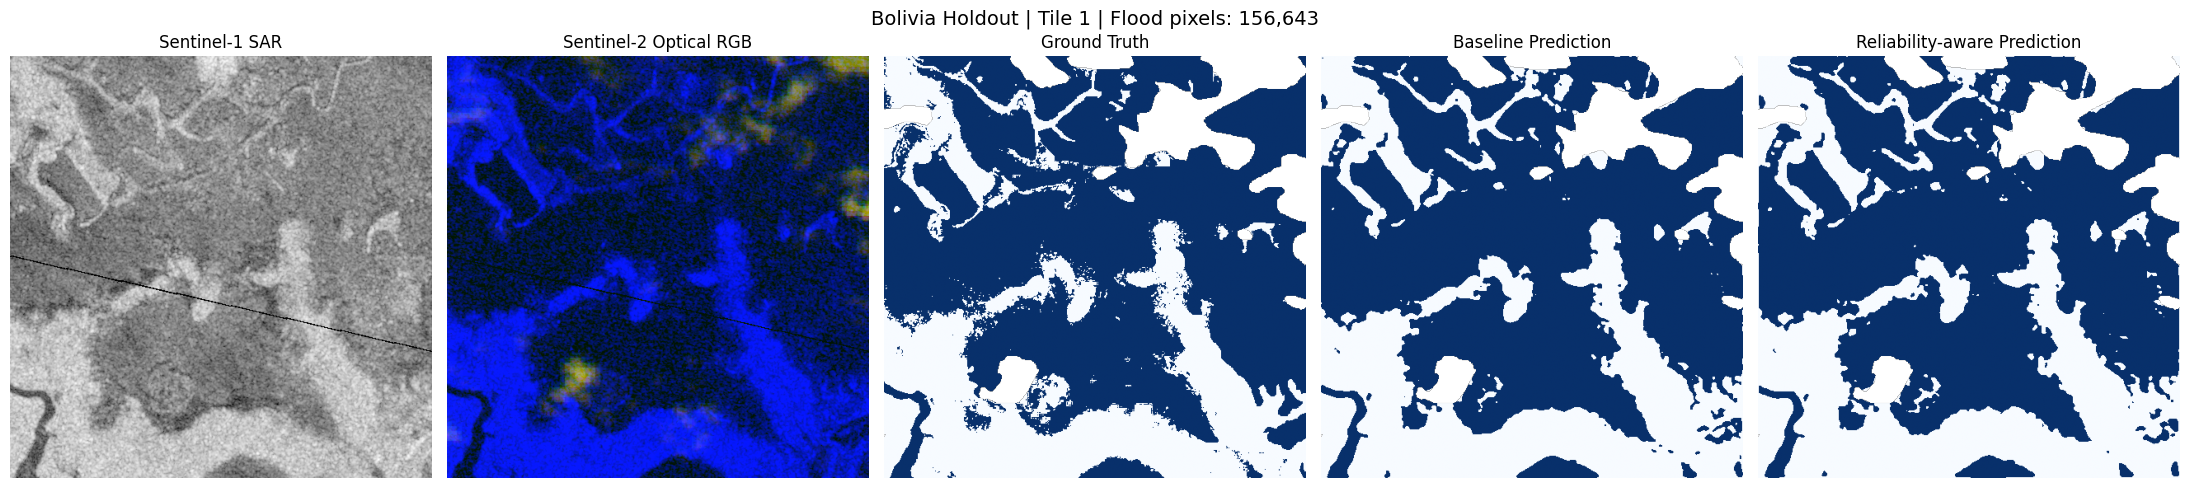

Saved: /content/bolivia_model_comparison.png


In [ ]:

import numpy as np
import matplotlib.pyplot as plt
import torch

# Find the Bolivia tile with the most labelled flood pixels
best_idx = 0
best_flood_pixels = -1

for i in range(len(bolivia_ds)):
    x, y = bolivia_ds[i]
    flood_pixels = ((y == 1) & (y != -1)).sum().item()

    if flood_pixels > best_flood_pixels:
        best_flood_pixels = flood_pixels
        best_idx = i

# Load selected tile
x, y = bolivia_ds[best_idx]
input_tensor = x.unsqueeze(0).to(DEVICE)

baseline.eval()
reliability_model.eval()

with torch.no_grad():
    baseline_pred = baseline(input_tensor).argmax(dim=1)[0].cpu().numpy()
    reliability_pred, weights = reliability_model(input_tensor)
    reliability_pred = reliability_pred.argmax(dim=1)[0].cpu().numpy()

# Prepare images
sar = x[0].numpy()
optical = x[[3, 2, 1]].numpy().transpose(1, 2, 0)

# Normalize optical RGB for display
valid_optical = optical[x[16].numpy() > 0]
if len(valid_optical):
    low, high = np.percentile(valid_optical, [2, 98])
    optical = np.clip((optical - low) / (high - low + 1e-8), 0, 1)

# Ground truth: -1 is unlabelled
ground_truth = np.ma.masked_where(y.numpy() == -1, y.numpy())

# Hide predictions where ground truth is unlabelled
baseline_display = np.ma.masked_where(y.numpy() == -1, baseline_pred)
reliability_display = np.ma.masked_where(y.numpy() == -1, reliability_pred)

# Plot
fig, axes = plt.subplots(1, 5, figsize=(22, 5))

axes[0].imshow(sar, cmap="gray")
axes[0].set_title("Sentinel-1 SAR")

axes[1].imshow(optical)
axes[1].set_title("Sentinel-2 Optical RGB")

axes[2].imshow(ground_truth, cmap="Blues", vmin=0, vmax=1)
axes[2].set_title("Ground Truth")

axes[3].imshow(baseline_display, cmap="Blues", vmin=0, vmax=1)
axes[3].set_title("Baseline Prediction")

axes[4].imshow(reliability_display, cmap="Blues", vmin=0, vmax=1)
axes[4].set_title("Reliability-aware Prediction")

for ax in axes:
    ax.axis("off")

plt.suptitle(
    f"Bolivia Holdout | Tile {best_idx} | "
    f"Flood pixels: {best_flood_pixels:,}",
    fontsize=14
)
plt.tight_layout()

# Save visual evidence
output_path = "/content/bolivia_model_comparison.png"
plt.savefig(output_path, dpi=200, bbox_inches="tight")
plt.show()

print("Saved:", output_path)